# Atividade 2 — Suavização e detecção de bordas

**Unidade 2 | Capítulo 1 | Tarefa 1**  
**Aluno:** Luiz Felipe Souza da Silva  
**Professor:** Rafael Carmo

O objetivo é comparar filtros de suavização e detectores de bordas em duas imagens de
FPGA e duas de contrabaixo. A análise considera quais detalhes são preservados e como
a suavização afeta as bordas, pensando no reconhecimento das duas classes.

## 1. Preparação

Execute as células em ordem. São necessárias as quatro fotos na pasta `dataset/originais`.
No Colab, o código usa o projeto disponível ou clona o repositório público.

Se necessário, instale as bibliotecas em uma célula separada:
`%pip install numpy pandas matplotlib pillow opencv-python`.

As imagens são convertidas para cinza e processadas no tamanho original. Os recortes
servem apenas para mostrar os detalhes; a média, a variância e a contagem de pixels de
borda são calculadas na imagem inteira. Não foi acrescentado ruído artificial.

In [1]:
from pathlib import Path
import json
import platform
import subprocess

import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import PIL
from IPython.display import display, Markdown

try:
    import google.colab
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'dataset' / 'originais').is_dir()), None)
if RAIZ is None and EM_COLAB:
    RAIZ = Path('/content/VC_iREDE')
    if not RAIZ.exists():
        subprocess.run(['git', 'clone', 'https://github.com/luix-felipe/VC_iREDE.git',
                        str(RAIZ)], check=True)
if RAIZ is None or not (RAIZ / 'dataset' / 'originais').is_dir():
    raise FileNotFoundError('Abra o notebook dentro do projeto com dataset/originais disponível.')

ORIGINAIS = RAIZ / 'dataset' / 'originais'
DERIVADAS = RAIZ / 'dataset' / 'derivadas' / 'atividade_2'
TABELAS = RAIZ / 'tabelas' / 'atividade_2'
FIGURAS = DERIVADAS / 'figuras'
for pasta in [DERIVADAS, TABELAS, FIGURAS]:
    pasta.mkdir(parents=True, exist_ok=True)

cv2.setNumThreads(2)
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 10, 'font.size': 10})
versoes = {'Python': platform.python_version(), 'NumPy': np.__version__,
           'pandas': pd.__version__, 'OpenCV': cv2.__version__,
           'Matplotlib': matplotlib.__version__, 'Pillow': PIL.__version__}
(TABELAS / 'ambiente.json').write_text(json.dumps(versoes, indent=2), encoding='utf-8')
print('Ambiente:', 'Google Colab' if EM_COLAB else 'local')


Ambiente: local


## 2. Seleção das imagens

As fotos foram feitas com um Galaxy S26, usando luz natural da janela do quarto, a cerca
de 20 cm da FPGA e 40 cm do contrabaixo. A cortina e os ajustes da câmera produziram
variações de iluminação.

| Imagem / classe | Ruído e desfoque observados | Outras limitações e possível origem |
|---|---|---|
| fpga_03.jpg — FPGA suja | Não identifiquei ruído aleatório significativo nem desfoque forte. Inscrições e soldas continuam visíveis. | A sujeira pertence à placa e não é ruído. A captura tem baixa exposição e pouco contraste nas trilhas. |
| fpga_04.jpg — FPGA limpa | Mesmo com ISO 2000, não identifiquei granulação intensa. Não há desfoque generalizado. | O tecido do fundo tem textura e gera muitas bordas, mas essa textura pertence à cena. |
| contrabaixo_04.jpg — Contrabaixo | Não identifiquei ruído significativo. O fundo do recorte está desfocado, mas a junção e os parafusos estão definidos. | Os reflexos são causados pela iluminação e pelo acabamento; o desfoque do fundo é compatível com diferença de distância da câmera. |
| contrabaixo_05.jpg — Contrabaixo | Não identifiquei ruído ou desfoque forte; cordas, trastes e marcadores permanecem distinguíveis. | A principal limitação é a baixa exposição, além dos reflexos e do pouco contraste nas partes escuras. |

Essas observações são visuais. Ruído é uma variação indesejada; sujeira, textura e reflexos
são elementos reais da cena. Desfoque é perda de definição, enquanto baixo contraste é
pouca diferença de intensidade. Portanto, uma foto escura não está necessariamente
desfocada. O processamento interno do celular também pode ter reduzido ruído antes de o
JPEG ser salvo, mas isso não pode ser medido sem uma imagem de referência.

Como não foi encontrado ruído intenso nas fotos, os filtros serão comparados primeiro nas
imagens reais e depois em um pequeno experimento com ruído artificial conhecido. O retângulo
laranja indica o detalhe de 420×420 pixels usado nas comparações.

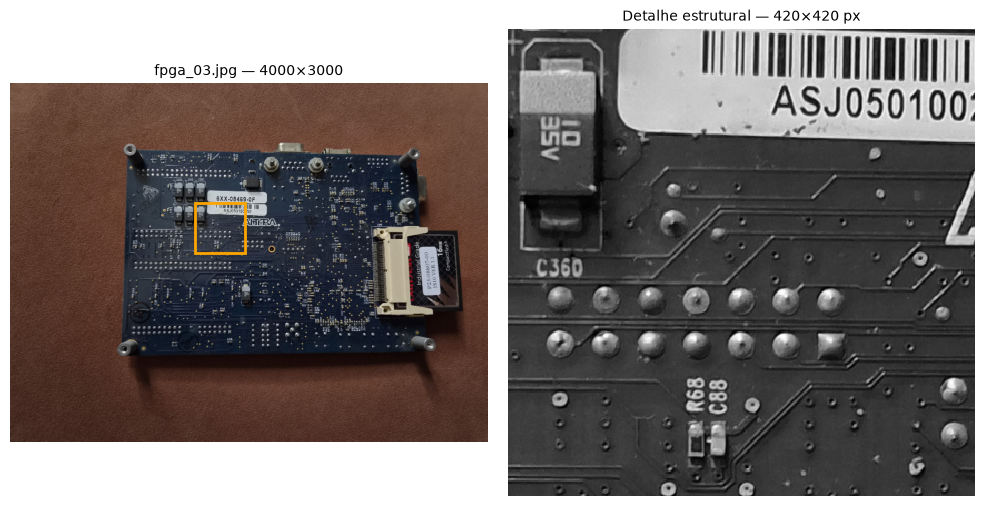

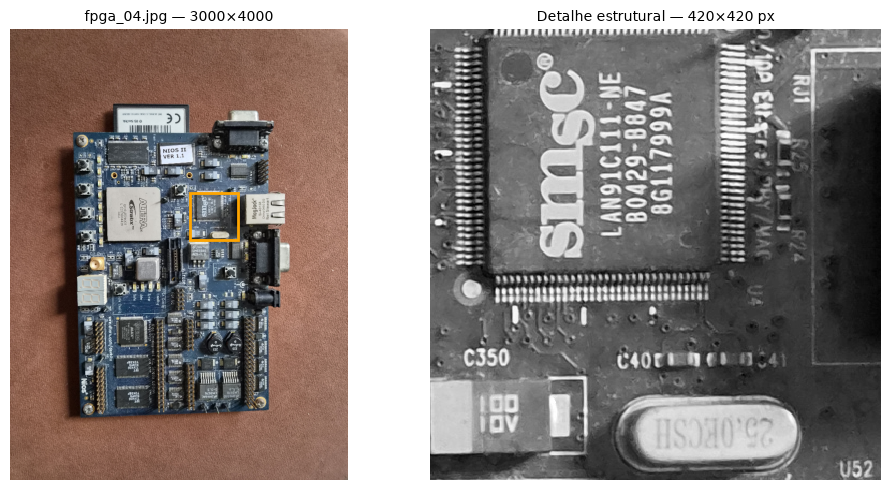

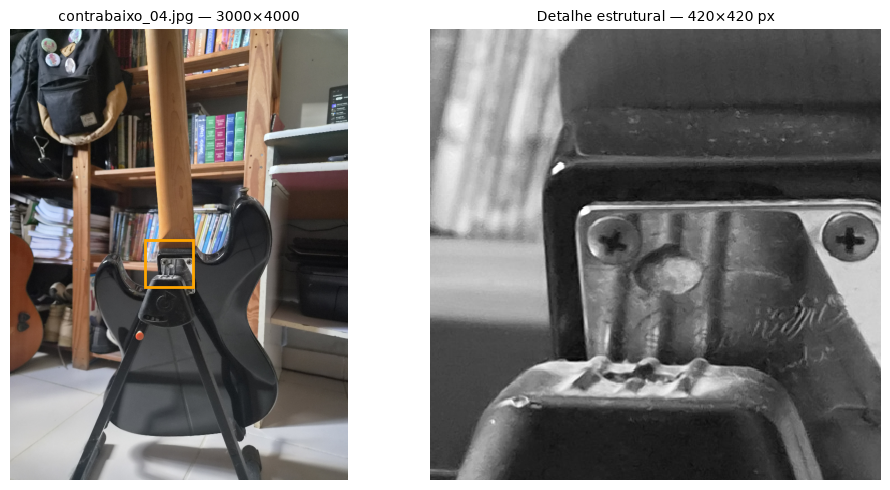

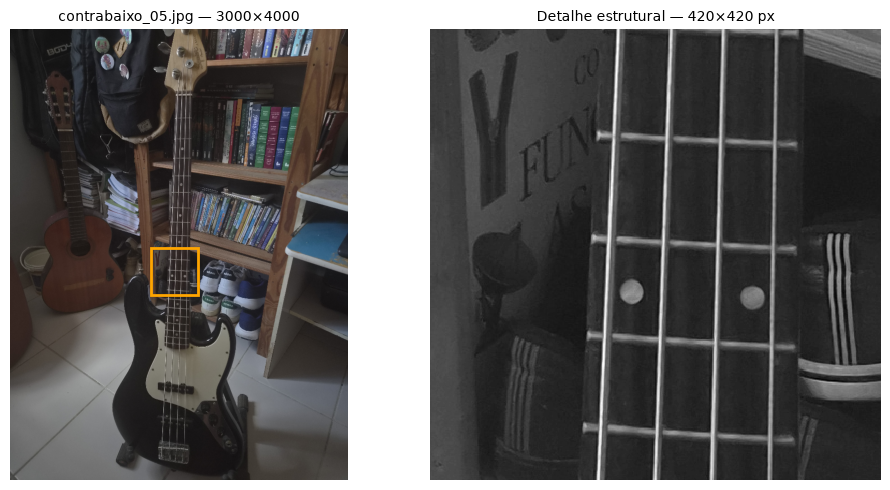

,Imagem,Classe,Largura (px),Altura (px)
0,fpga_03.jpg,fpga,4000,3000
1,fpga_04.jpg,fpga,3000,4000
2,contrabaixo_04.jpg,contrabaixo,3000,4000
3,contrabaixo_05.jpg,contrabaixo,3000,4000


In [2]:
SELECAO = [
    {'arquivo': 'fpga_03.jpg', 'classe': 'fpga',
     'detalhe': (1550, 1000, 1970, 1420)},
    {'arquivo': 'fpga_04.jpg', 'classe': 'fpga',
     'detalhe': (1600, 1450, 2020, 1870)},
    {'arquivo': 'contrabaixo_04.jpg', 'classe': 'contrabaixo',
     'detalhe': (1200, 1870, 1620, 2290)},
    {'arquivo': 'contrabaixo_05.jpg', 'classe': 'contrabaixo',
     'detalhe': (1250, 1940, 1670, 2360)},
]

def carregar_rgb(caminho):
    with Image.open(caminho) as imagem:
        return np.array(ImageOps.exif_transpose(imagem).convert('RGB'))

def recortar(imagem, caixa):
    x0, y0, x1, y1 = caixa
    return imagem[y0:y1, x0:x1]

def salvar_png(imagem, caminho):
    caminho.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(imagem).save(caminho, compress_level=6)

def finalizar_figura(figura, nome):
    figura.tight_layout()
    figura.savefig(FIGURAS / f'{nome}.png', dpi=120, bbox_inches='tight')
    plt.show()
    plt.close(figura)

def mostrar_tabela(quadro, colunas):
    # Exibe só as colunas solicitadas, com cabeçalhos legíveis e sem caminhos técnicos.
    vista = quadro[list(colunas)].rename(columns=colunas)
    with pd.option_context('display.max_columns', None, 'display.max_colwidth', None,
                           'display.max_rows', 100, 'display.float_format', '{:.2f}'.format):
        display(vista)

IMAGENS = {}
linhas_selecao = []
for item in SELECAO:
    nome, classe = item['arquivo'], item['classe']
    rgb = carregar_rgb(ORIGINAIS / classe / nome)
    cinza = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    altura, largura = cinza.shape
    for chave in ['detalhe']:
        x0, y0, x1, y1 = item[chave]
        assert 0 <= x0 < x1 <= largura and 0 <= y0 < y1 <= altura
    IMAGENS[nome] = cinza
    salvar_png(cinza, DERIVADAS / 'originais_cinza' / classe / f'{Path(nome).stem}.png')
    linhas_selecao.append({'arquivo': nome, 'classe': classe, 'largura_px': largura,
                           'altura_px': altura, 'recorte_detalhe': str(item['detalhe'])})
    figura, eixos = plt.subplots(1, 2, figsize=(10, 5))
    eixos[0].imshow(rgb[::4, ::4], extent=(0, largura, altura, 0))
    for chave, cor in [('detalhe', 'orange')]:
        x0, y0, x1, y1 = item[chave]
        eixos[0].add_patch(Rectangle((x0, y0), x1-x0, y1-y0,
                                   fill=False, edgecolor=cor, linewidth=2))
    eixos[0].set_title(f'{nome} — {largura}×{altura}')
    eixos[1].imshow(recortar(cinza, item['detalhe']), cmap='gray', vmin=0, vmax=255,
                    interpolation='nearest')
    eixos[1].set_title('Detalhe estrutural — 420×420 px')
    for eixo in eixos:
        eixo.axis('off')
    finalizar_figura(figura, f'selecao_{Path(nome).stem}')
    del rgb

selecao = pd.DataFrame(linhas_selecao)
selecao.to_csv(TABELAS / 'selecao_imagens.csv', index=False)
mostrar_tabela(selecao, {'arquivo': 'Imagem', 'classe': 'Classe',
                        'largura_px': 'Largura (px)', 'altura_px': 'Altura (px)'})

## 3. Filtros de suavização

| Filtro | Configurações | Funcionamento |
|---|---|---|
| Média | 3×3 e 5×5 | Substitui o pixel pela média dos vizinhos. |
| Gaussiano | σ=1 e σ=3 | Dá mais peso aos pixels próximos do centro. |
| Mediana | 3×3 e 5×5 | Usa o valor central dos vizinhos ordenados. |

No Gaussiano, as janelas são 7×7 e 19×19, cobrindo aproximadamente três desvios-padrão
para cada lado. Todos os filtros usam repetição dos pixels na borda da imagem.

As tabelas mostram **média e variância** dos níveis de cinza. Uma variância menor indica
menos variação, mas também pode significar perda de textura e detalhes. Por isso, os
números são comparados com as imagens.

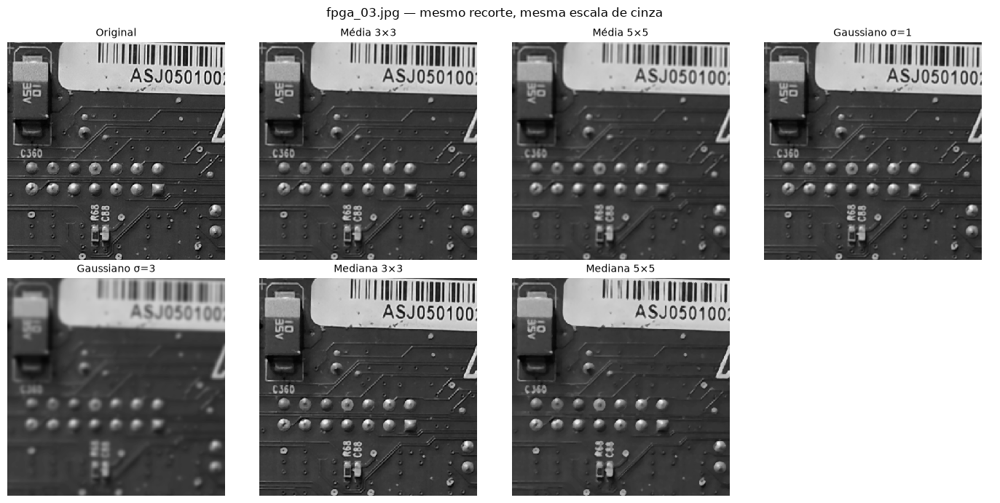

,Filtro,Média,Variância
0,Original,62.85,1172.60
1,Média 3×3,62.85,1104.35
2,Média 5×5,62.85,1037.06
3,Gaussiano σ=1,62.85,1086.37
4,Gaussiano σ=3,62.85,924.88
5,Mediana 3×3,62.76,1141.43
6,Mediana 5×5,62.53,1094.26


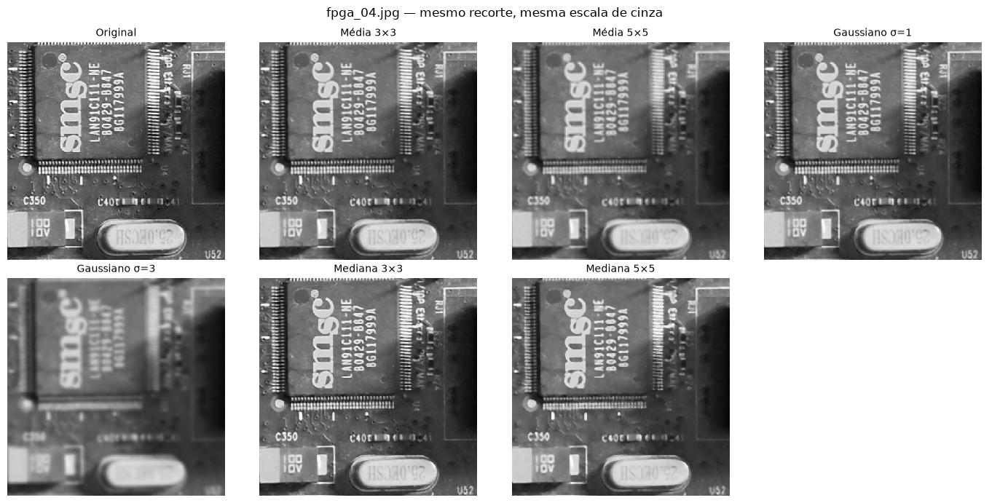

,Filtro,Média,Variância
7,Original,104.55,2214.84
8,Média 3×3,104.55,2066.66
9,Média 5×5,104.55,1931.08
10,Gaussiano σ=1,104.55,2030.35
11,Gaussiano σ=3,104.55,1721.98
12,Mediana 3×3,104.41,2144.07
13,Mediana 5×5,104.10,2056.20


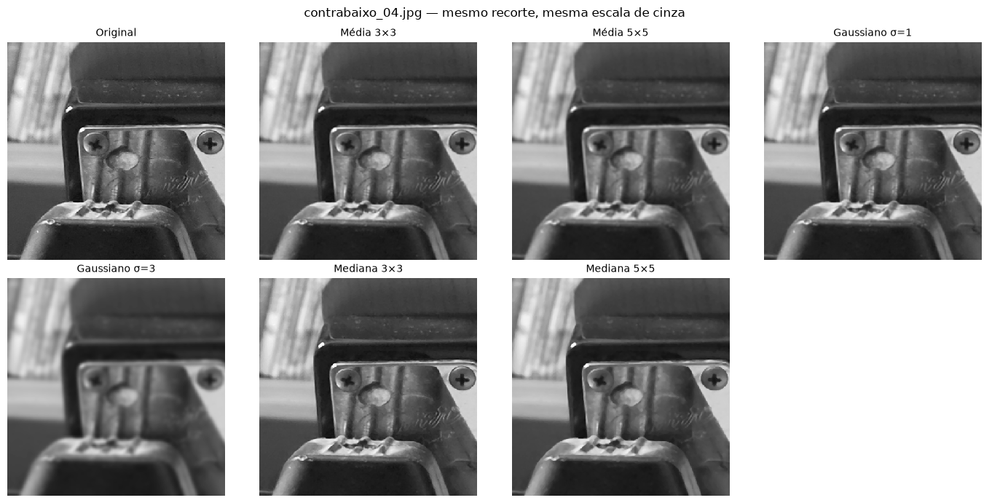

,Filtro,Média,Variância
14,Original,96.24,3644.16
15,Média 3×3,96.24,3629.53
16,Média 5×5,96.24,3611.40
17,Gaussiano σ=1,96.24,3624.91
18,Gaussiano σ=3,96.24,3556.61
19,Mediana 3×3,96.24,3638.91
20,Mediana 5×5,96.23,3633.15


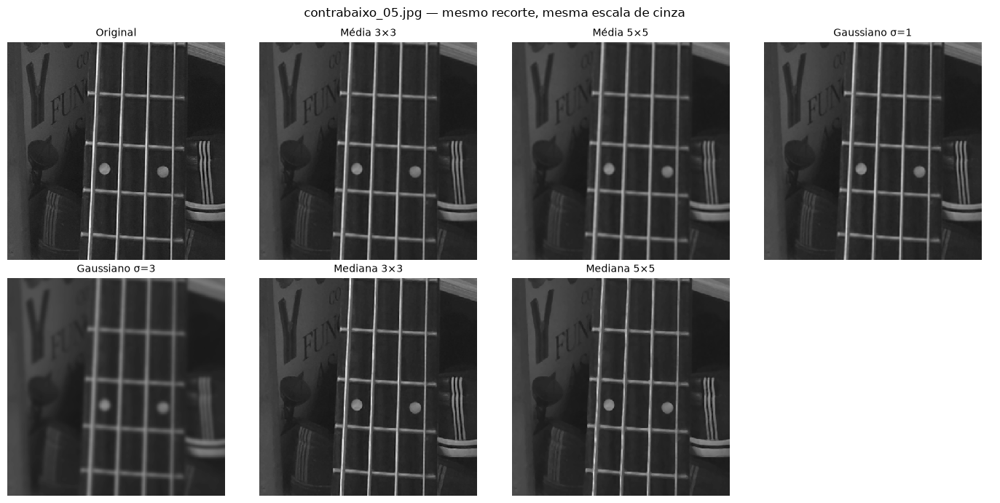

,Filtro,Média,Variância
21,Original,68.01,1581.28
22,Média 3×3,68.01,1546.60
23,Média 5×5,68.01,1515.03
24,Gaussiano σ=1,68.01,1538.22
25,Gaussiano σ=3,68.01,1458.68
26,Mediana 3×3,67.96,1563.71
27,Mediana 5×5,67.83,1534.69


In [3]:
FILTROS = {
    'original': 'Original',
    'media_3': 'Média 3×3', 'media_5': 'Média 5×5',
    'gauss_1': 'Gaussiano σ=1', 'gauss_3': 'Gaussiano σ=3',
    'mediana_3': 'Mediana 3×3', 'mediana_5': 'Mediana 5×5',
}

def suavizar(imagem, filtro):
    if filtro == 'original':
        return imagem.copy()
    if filtro.startswith('media_'):
        k = int(filtro.split('_')[1])
        return cv2.blur(imagem, (k, k), borderType=cv2.BORDER_REPLICATE)
    if filtro.startswith('gauss_'):
        sigma = int(filtro.split('_')[1])
        k = 6 * sigma + 1
        return cv2.GaussianBlur(imagem, (k, k), sigmaX=sigma, sigmaY=sigma,
                                borderType=cv2.BORDER_REPLICATE)
    if filtro.startswith('mediana_'):
        return cv2.medianBlur(imagem, int(filtro.split('_')[1]))
    raise ValueError(f'Filtro desconhecido: {filtro}')

def gradientes(imagem, operador):
    if operador == 'Sobel':
        gx = cv2.Sobel(imagem, cv2.CV_32F, 1, 0, ksize=3, scale=1/4,
                       borderType=cv2.BORDER_REPLICATE)
        gy = cv2.Sobel(imagem, cv2.CV_32F, 0, 1, ksize=3, scale=1/4,
                       borderType=cv2.BORDER_REPLICATE)
    elif operador == 'Prewitt':
        kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32) / 3
        gx = cv2.filter2D(imagem, cv2.CV_32F, kx, borderType=cv2.BORDER_REPLICATE)
        gy = cv2.filter2D(imagem, cv2.CV_32F, kx.T, borderType=cv2.BORDER_REPLICATE)
    else:
        raise ValueError(operador)
    return gx, gy, cv2.magnitude(gx, gy)

linhas_suavizacao = []
for item in SELECAO:
    nome = item['arquivo']
    original = IMAGENS[nome]
    figura, eixos = plt.subplots(2, 4, figsize=(14, 7))
    for eixo, (chave, rotulo) in zip(eixos.flat, FILTROS.items()):
        resultado = suavizar(original, chave)
        detalhe = recortar(resultado, item['detalhe'])
        valores = resultado.astype(np.float32)
        linhas_suavizacao.append({
            'imagem': nome, 'classe': item['classe'], 'filtro': rotulo,
            'media_cinza': float(valores.mean()), 'variancia_cinza': float(valores.var()),
        })
        eixo.imshow(detalhe, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        eixo.set_title(rotulo)
        eixo.axis('off')
        if chave != 'original':
            salvar_png(resultado, DERIVADAS / 'suavizacao' / item['classe'] /
                        f'{Path(nome).stem}_{chave}.png')
        del valores, resultado
    eixos.flat[-1].axis('off')
    figura.suptitle(f'{nome} — mesmo recorte, mesma escala de cinza')
    finalizar_figura(figura, f'suavizacao_{Path(nome).stem}')
    parcial = pd.DataFrame(linhas_suavizacao).query('imagem == @nome')
    mostrar_tabela(parcial, {'filtro': 'Filtro', 'media_cinza': 'Média',
        'variancia_cinza': 'Variância'})

suavizacao = pd.DataFrame(linhas_suavizacao)
suavizacao.to_csv(TABELAS / 'suavizacao.csv', index=False)

### Comparação e escolha do filtro

As janelas maiores suavizam mais, mas deixam os detalhes menos definidos. Nas imagens reais,
o Gaussiano σ=3 apagou parte das trilhas, inscrições e contornos. A mediana 3×3 preservou
mais detalhes, mas não havia ruído sal e pimenta evidente para justificar sua aplicação.

Foi escolhido **Gaussiano σ=1** para repetir a detecção de bordas porque é a configuração
menos agressiva entre os Gaussianos testados. Essa escolha permite cumprir a comparação
antes/depois do enunciado; não significa que filtrar seja melhor do que manter a imagem
original. Nas capturas do Galaxy S26, a suavização reduziu mais informações reais do que
ruído visível. O filtro também não corrige baixa exposição, sujeira, reflexos ou desfoque.

In [4]:
FILTRO_ESCOLHIDO = {item['arquivo']: 'gauss_1' for item in SELECAO}
escolha = pd.DataFrame([
    {'imagem': item['arquivo'], 'filtro_escolhido': FILTROS[FILTRO_ESCOLHIDO[item['arquivo']]]}
    for item in SELECAO
])
escolha.to_csv(TABELAS / 'escolha_filtros.csv', index=False)

### Experimento controlado com ruído artificial

Como as fotografias não apresentam ruído visual significativo, foi usado um recorte da
`fpga_04.jpg` como referência para criar duas degradações conhecidas:

- **Ruído gaussiano:** valores aleatórios com média zero e desvio-padrão 18.
- **Sal e pimenta:** 5% dos pixels substituídos, metade por 0 e metade por 255.

A semente aleatória é fixa, então o resultado é reproduzível. O objetivo é observar quando
cada filtro é apropriado, não simular exatamente o processamento da câmera. Não foi usado
downscale: reduzir e ampliar a imagem demonstra perda de resolução e interpolação, não isola
o comportamento dos filtros diante desses dois tipos de ruído.

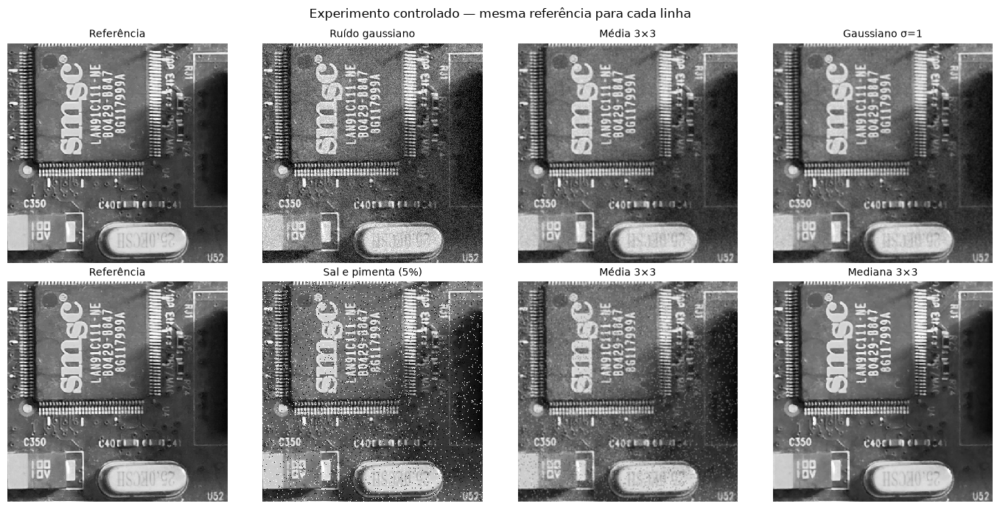

In [5]:
item_ruido = next(item for item in SELECAO if item['arquivo'] == 'fpga_04.jpg')
referencia_ruido = recortar(IMAGENS['fpga_04.jpg'], item_ruido['detalhe']).copy()
gerador = np.random.default_rng(42)

ruido_gaussiano = gerador.normal(0, 18, referencia_ruido.shape)
com_gaussiano = np.clip(referencia_ruido.astype(np.float32) + ruido_gaussiano,
                        0, 255).astype(np.uint8)

com_impulsivo = referencia_ruido.copy()
posicoes = gerador.random(referencia_ruido.shape)
com_impulsivo[posicoes < 0.025] = 0
com_impulsivo[(posicoes >= 0.025) & (posicoes < 0.05)] = 255

comparacoes_ruido = [
    referencia_ruido, com_gaussiano,
    suavizar(com_gaussiano, 'media_3'), suavizar(com_gaussiano, 'gauss_1'),
    referencia_ruido, com_impulsivo,
    suavizar(com_impulsivo, 'media_3'), suavizar(com_impulsivo, 'mediana_3')
]
titulos_ruido = [
    'Referência', 'Ruído gaussiano', 'Média 3×3', 'Gaussiano σ=1',
    'Referência', 'Sal e pimenta (5%)', 'Média 3×3', 'Mediana 3×3'
]
figura, eixos = plt.subplots(2, 4, figsize=(14, 7))
for eixo, resultado, titulo in zip(eixos.flat, comparacoes_ruido, titulos_ruido):
    eixo.imshow(resultado, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    eixo.set_title(titulo)
    eixo.axis('off')
figura.suptitle('Experimento controlado — mesma referência para cada linha')
finalizar_figura(figura, 'ruido_sintetico_controlado')

No ruído gaussiano, a média e o Gaussiano atenuam a granulação, mas também deixam as
bordas menos definidas. O Gaussiano σ=1 produz uma transição mais gradual porque dá maior
peso aos vizinhos próximos. No sal e pimenta, o filtro da média espalha os valores extremos,
enquanto a mediana remove a maior parte dos pontos sem misturá-los da mesma forma.

Esse resultado mostra que a mediana é adequada para ruído impulsivo e que o Gaussiano pode
ser útil quando há variações aleatórias semelhantes ao modelo gaussiano. Ele não demonstra
que as fotos reais precisam desses filtros: nelas, a sujeira e os reflexos devem continuar
sendo tratados como conteúdo da cena.

## 4. Bordas antes da suavização

Sobel e Prewitt calculam os gradientes em X e Y. A magnitude combina os dois:
`sqrt(Gx² + Gy²)`. O gradiente X destaca mudanças na direção horizontal, como bordas
verticais; Y destaca mudanças na direção vertical.

Os cálculos usam ponto flutuante para preservar valores negativos. Sobel é dividido
por 4 e Prewitt por 3 para comparar suas amplitudes. Nas figuras, X e Y usam a mesma
escala de −255 a 255; a magnitude usa 0 a 255.

No Canny são testados os limiares **40/80, 80/160 e 120/240**. O limiar alto seleciona
bordas fortes; o baixo permite manter bordas fracas ligadas a elas. Usa-se janela de
gradiente 3×3 e magnitude euclidiana (`L2gradient=True`). Nesta etapa, a entrada é a
imagem em cinza, sem filtro de suavização anterior.

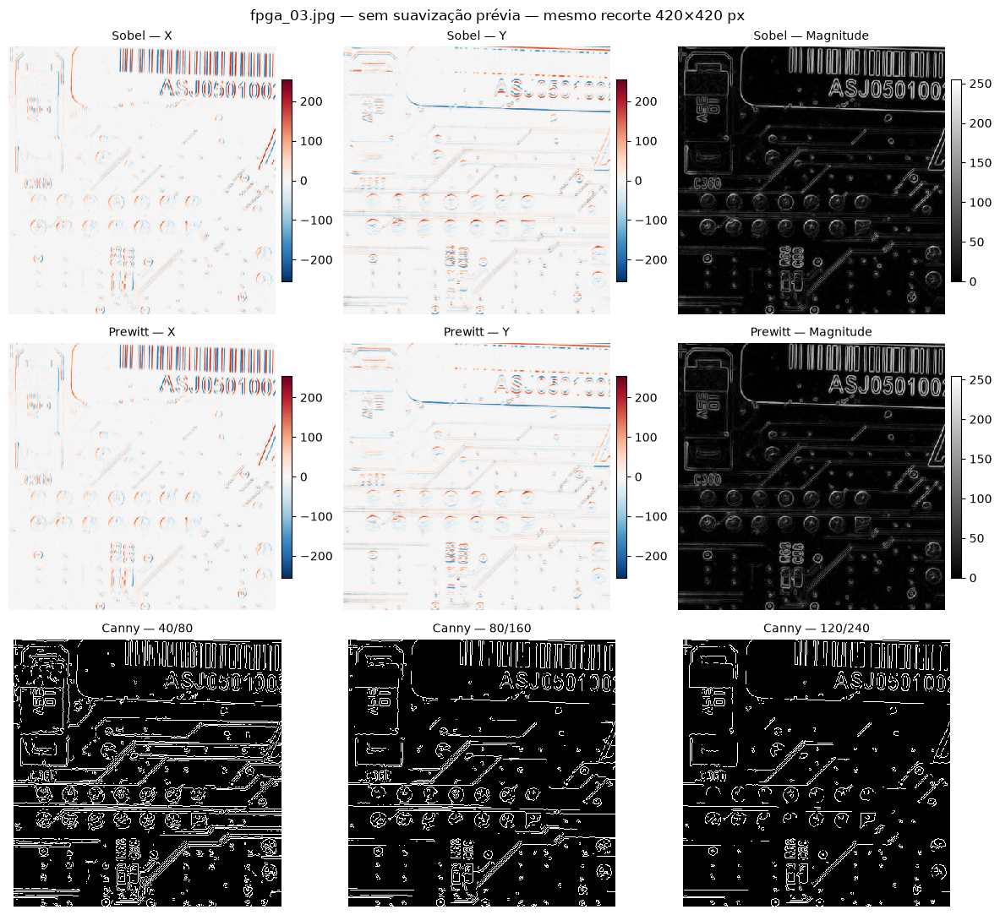

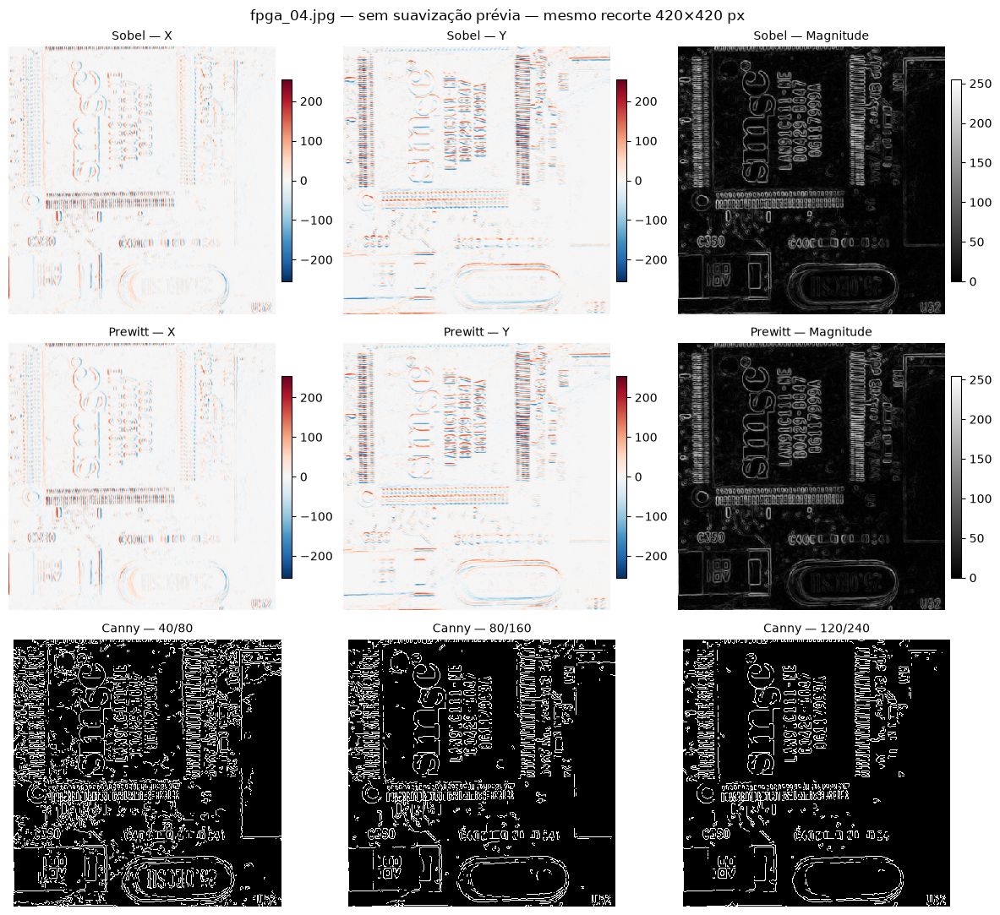

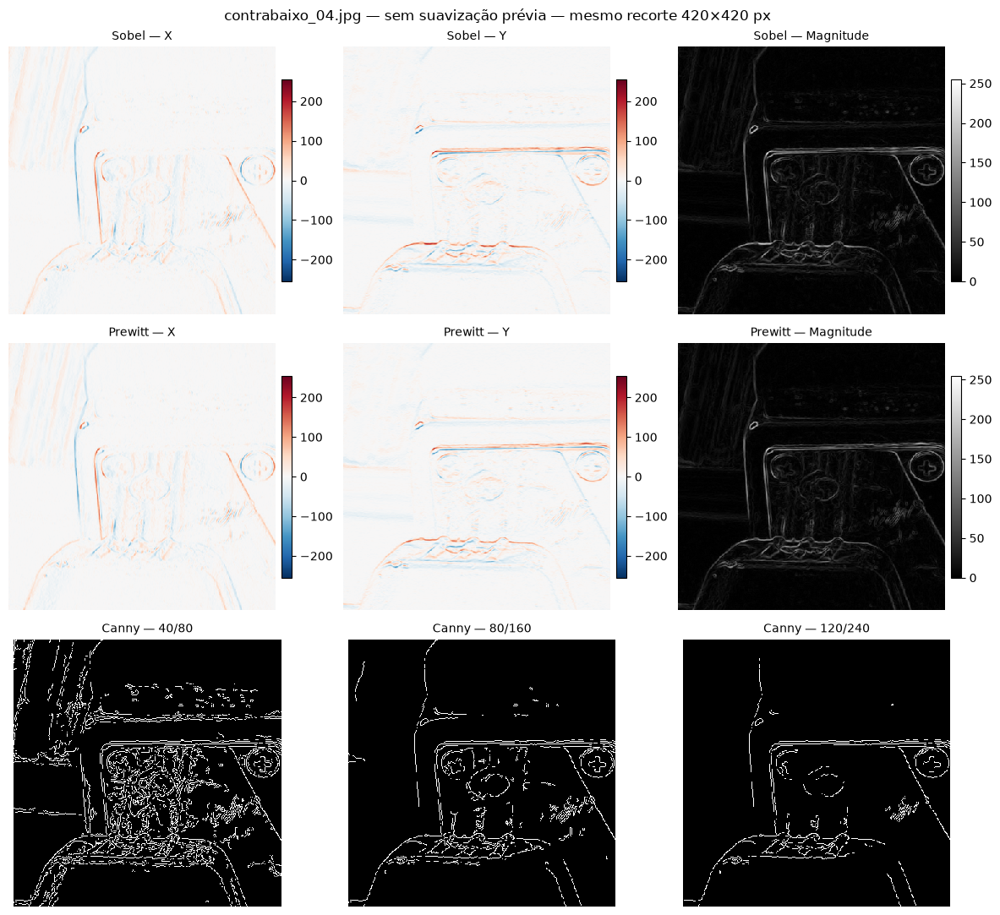

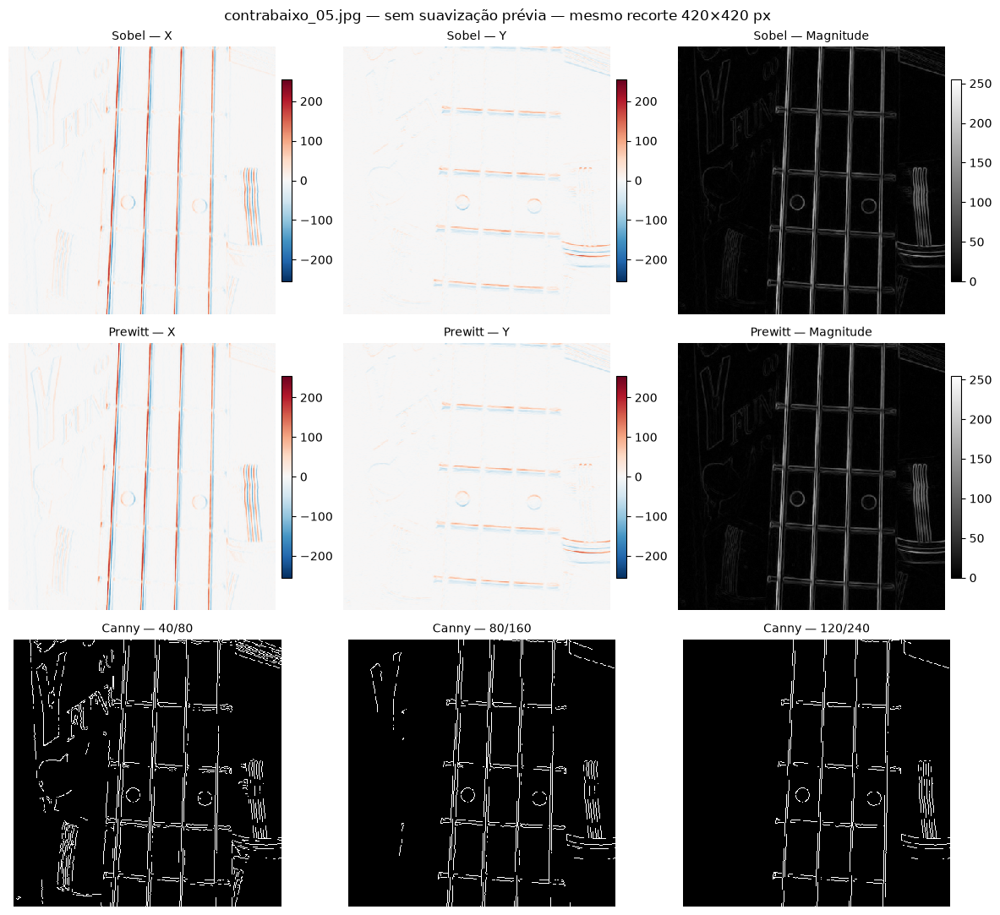

,Imagem,Método,Pixels de borda
0,fpga_03.jpg,Sobel,1033420
1,fpga_03.jpg,Prewitt,1004574
2,fpga_03.jpg,Canny 40/80,1073745
3,fpga_03.jpg,Canny 80/160,298156
4,fpga_03.jpg,Canny 120/240,216465
5,fpga_04.jpg,Sobel,3059636
6,fpga_04.jpg,Prewitt,2963230
7,fpga_04.jpg,Canny 40/80,2647702
8,fpga_04.jpg,Canny 80/160,1192609
9,fpga_04.jpg,Canny 120/240,450806


In [6]:
PARES_CANNY = [(40, 80), (80, 160), (120, 240)]
LIMIAR_GRADIENTE = 20.0
METODOS = ['Sobel', 'Prewitt'] + [f'Canny {a}/{b}' for a, b in PARES_CANNY]
REGISTROS_BORDAS = []

def metricas_bordas(mascara):
    return {'pixels_borda': int(np.count_nonzero(mascara))}

def detectar_e_registrar(item, imagem, etapa):
    nome = item['arquivo']
    pasta = DERIVADAS / 'bordas' / etapa / item['classe']
    figura, eixos = plt.subplots(3, 3, figsize=(12, 11))
    for linha, operador in enumerate(['Sobel', 'Prewitt']):
        gx, gy, magnitude = gradientes(imagem, operador)
        for coluna, (matriz, eixo_nome) in enumerate([(gx, 'X'), (gy, 'Y'), (magnitude, 'Magnitude')]):
            eixo = eixos[linha, coluna]
            assinado = coluna < 2
            exibicao = eixo.imshow(recortar(matriz, item['detalhe']),
                cmap='RdBu_r' if assinado else 'gray', vmin=-255 if assinado else 0,
                vmax=255, interpolation='nearest')
            eixo.set_title(f'{operador} — {eixo_nome}')
            eixo.axis('off')
            figura.colorbar(exibicao, ax=eixo, fraction=0.035, pad=0.02)
        mascara = (magnitude >= LIMIAR_GRADIENTE).astype(np.uint8) * 255
        salvar_png(mascara, pasta / f'{Path(nome).stem}_{operador.lower()}.png')
        REGISTROS_BORDAS.append({'imagem': nome, 'classe': item['classe'],
            'etapa': etapa, 'metodo': operador, **metricas_bordas(mascara)})
        del gx, gy, magnitude, mascara
    for coluna, (baixo, alto) in enumerate(PARES_CANNY):
        bordas = cv2.Canny(imagem, baixo, alto, apertureSize=3, L2gradient=True)
        eixos[2, coluna].imshow(recortar(bordas, item['detalhe']), cmap='gray',
                                vmin=0, vmax=255, interpolation='nearest')
        eixos[2, coluna].set_title(f'Canny — {baixo}/{alto}')
        eixos[2, coluna].axis('off')
        salvar_png(bordas, pasta / f'{Path(nome).stem}_canny_{baixo}_{alto}.png')
        REGISTROS_BORDAS.append({'imagem': nome, 'classe': item['classe'],
            'etapa': etapa, 'metodo': f'Canny {baixo}/{alto}', **metricas_bordas(bordas)})
    titulo = 'sem suavização prévia' if etapa == 'antes' else 'após Gaussiano σ=1'
    figura.suptitle(f'{nome} — {titulo} — mesmo recorte 420×420 px')
    finalizar_figura(figura, f'gradientes_{etapa}_{Path(nome).stem}')

for item in SELECAO:
    detectar_e_registrar(item, IMAGENS[item['arquivo']], 'antes')

bordas_antes = pd.DataFrame(REGISTROS_BORDAS)
bordas_antes.to_csv(TABELAS / 'bordas_antes.csv', index=False)
mostrar_tabela(bordas_antes, {'imagem': 'Imagem', 'metodo': 'Método',
    'pixels_borda': 'Pixels de borda'})

### Comparação dos métodos

Sobel e Prewitt produzem resultados parecidos e bordas mais espessas. Canny produz
traços mais finos. Com limiares baixos, aparecem mais detalhes e textura; com limiares
altos, algumas bordas fracas desaparecem.

Para contar pixels de borda em Sobel e Prewitt, foi usada magnitude ≥20. Esse valor
não tem a mesma escala dos limiares do Canny. A comparação da contagem deve ser feita
principalmente antes e depois **do mesmo método**.

Respostas pequenas podem vir de ruído, mas também de textura, inscrições e reflexos.
Bordas no tecido ou nos livros podem atrapalhar o reconhecimento do objeto, embora
sejam bordas reais da cena. Não há uma marcação de referência para contar falsos positivos.

## 5. Bordas depois da suavização

Após aplicar Gaussiano σ=1, são repetidos Sobel, Prewitt e Canny com os mesmos parâmetros.
As tabelas comparam a quantidade de pixels de borda. A continuidade e a presença de
respostas indesejadas são avaliadas nas figuras. A redução da contagem, sozinha, não
prova melhora, pois algumas bordas importantes também podem desaparecer.

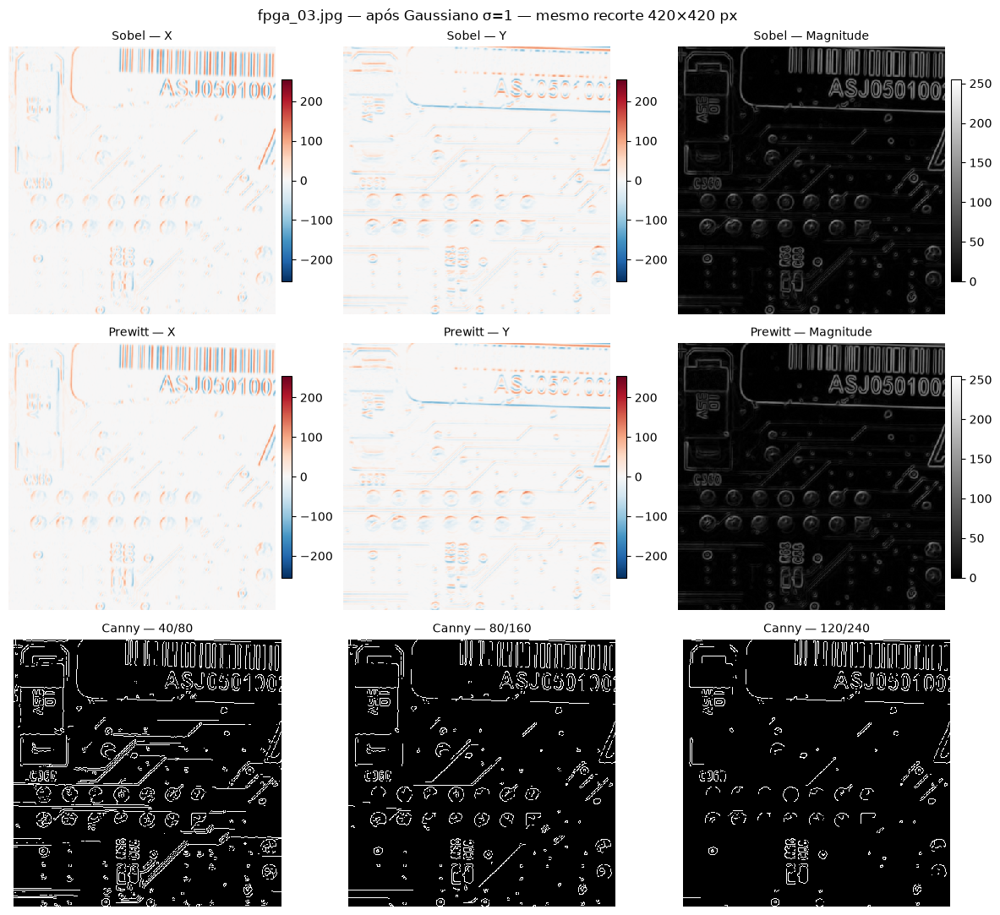

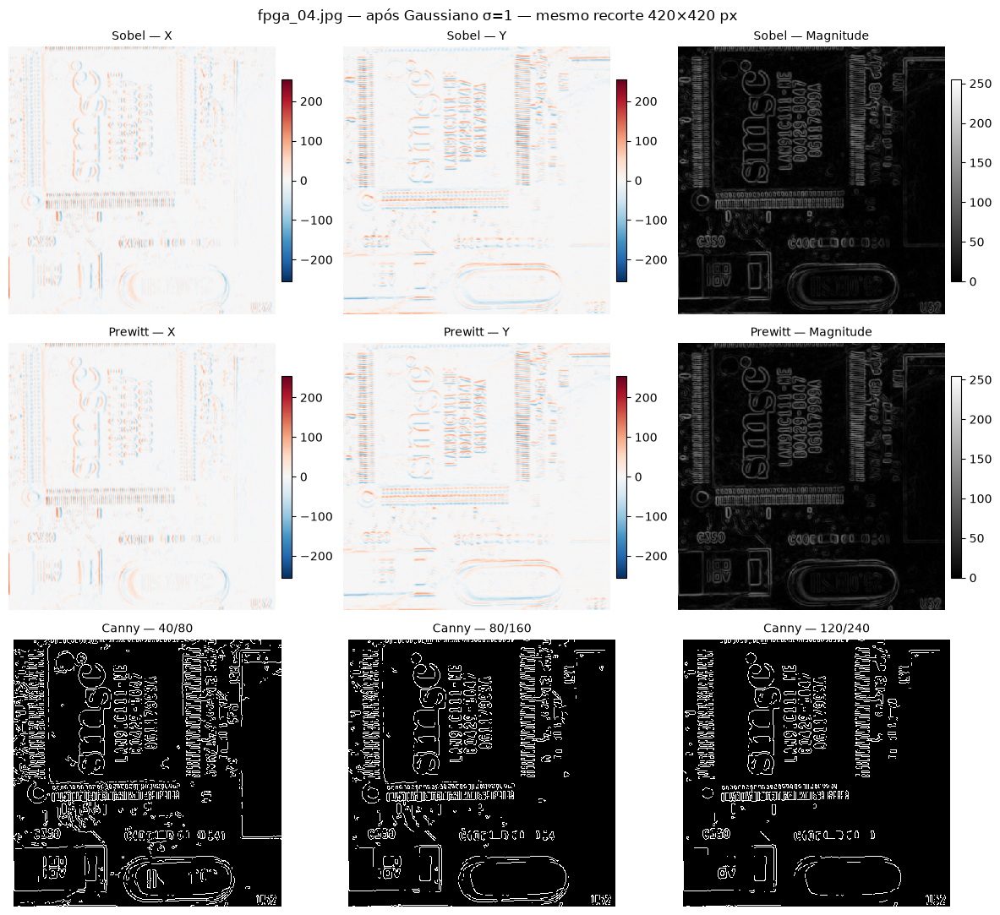

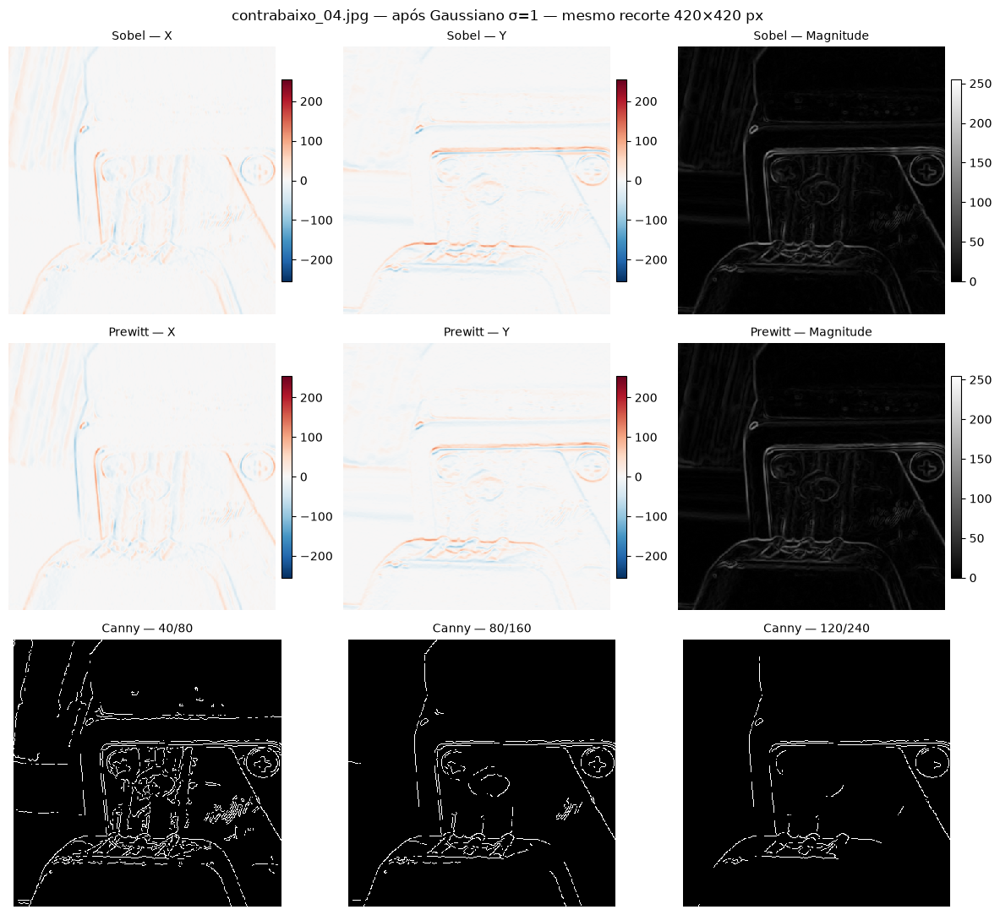

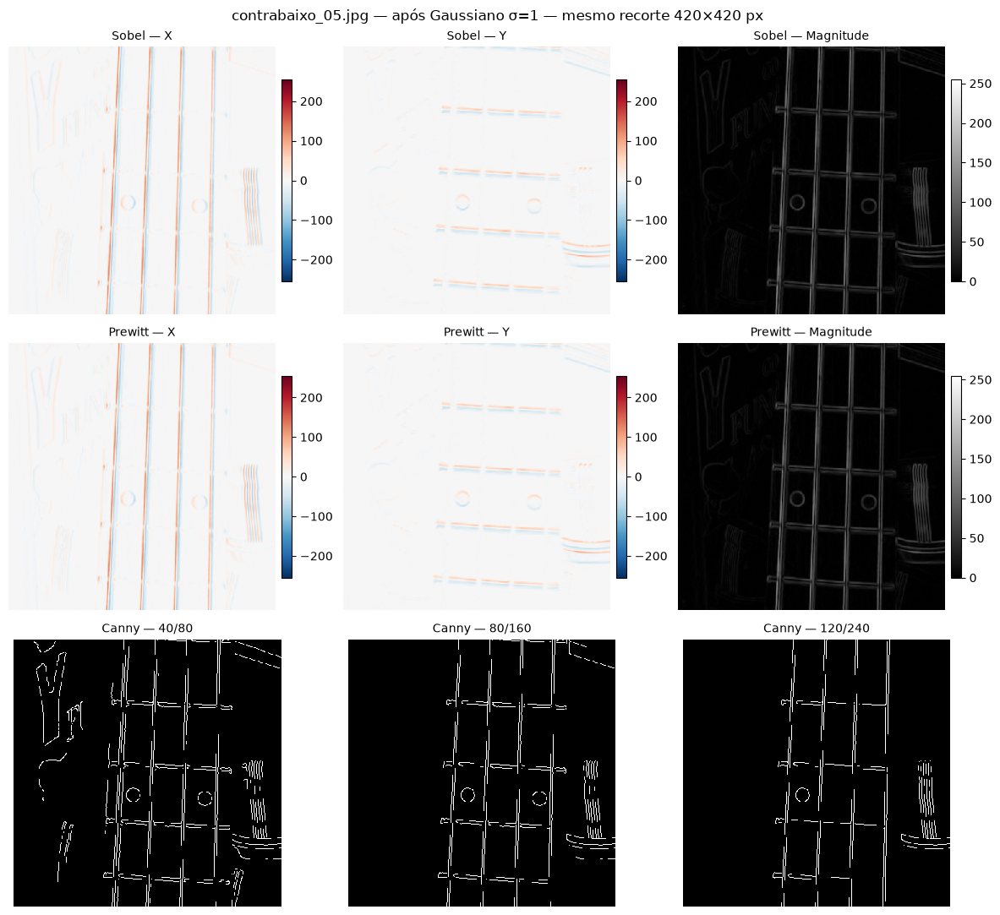

,Imagem,Método,Pixels antes,Pixels depois,Redução (%)
0,fpga_03.jpg,Sobel,1033420,711689,31.13
1,fpga_03.jpg,Prewitt,1004574,708187,29.50
2,fpga_03.jpg,Canny 40/80,1073745,377201,64.87
3,fpga_03.jpg,Canny 80/160,298156,194929,34.62
4,fpga_03.jpg,Canny 120/240,216465,148375,31.46


,Imagem,Método,Pixels antes,Pixels depois,Redução (%)
5,fpga_04.jpg,Sobel,3059636,1689492,44.78
6,fpga_04.jpg,Prewitt,2963230,1662035,43.91
7,fpga_04.jpg,Canny 40/80,2647702,1440667,45.59
8,fpga_04.jpg,Canny 80/160,1192609,368582,69.09
9,fpga_04.jpg,Canny 120/240,450806,261352,42.03


,Imagem,Método,Pixels antes,Pixels depois,Redução (%)
10,contrabaixo_04.jpg,Sobel,338778,279270,17.57
11,contrabaixo_04.jpg,Prewitt,334390,278467,16.72
12,contrabaixo_04.jpg,Canny 40/80,260817,129916,50.19
13,contrabaixo_04.jpg,Canny 80/160,80613,47055,41.63
14,contrabaixo_04.jpg,Canny 120/240,37842,24450,35.39


,Imagem,Método,Pixels antes,Pixels depois,Redução (%)
15,contrabaixo_05.jpg,Sobel,620510,486194,21.65
16,contrabaixo_05.jpg,Prewitt,614809,483491,21.36
17,contrabaixo_05.jpg,Canny 40/80,402128,260181,35.30
18,contrabaixo_05.jpg,Canny 80/160,229448,138169,39.78
19,contrabaixo_05.jpg,Canny 120/240,150213,75724,49.59


In [7]:
for item in SELECAO:
    filtrada = suavizar(IMAGENS[item['arquivo']], FILTRO_ESCOLHIDO[item['arquivo']])
    detectar_e_registrar(item, filtrada, 'depois')

bordas = pd.DataFrame(REGISTROS_BORDAS)
bordas_depois = bordas.query("etapa == 'depois'").copy()
bordas_depois.to_csv(TABELAS / 'bordas_depois.csv', index=False)
chaves = ['imagem', 'classe', 'metodo']
comparacao = bordas_antes.merge(bordas_depois, on=chaves, suffixes=('_antes', '_depois'),
                               validate='one_to_one')
comparacao['reducao_pixels_percentual'] = 100 * (
    1 - comparacao['pixels_borda_depois'] / comparacao['pixels_borda_antes'].replace(0, np.nan))
comparacao.to_csv(TABELAS / 'comparacao_bordas.csv', index=False)

for item in SELECAO:
    nome = item['arquivo']
    mostrar_tabela(comparacao.query('imagem == @nome'), {
        'imagem': 'Imagem', 'metodo': 'Método',
        'pixels_borda_antes': 'Pixels antes', 'pixels_borda_depois': 'Pixels depois',
        'reducao_pixels_percentual': 'Redução (%)'})

canny_comparacao = comparacao.query("metodo == 'Canny 80/160'")

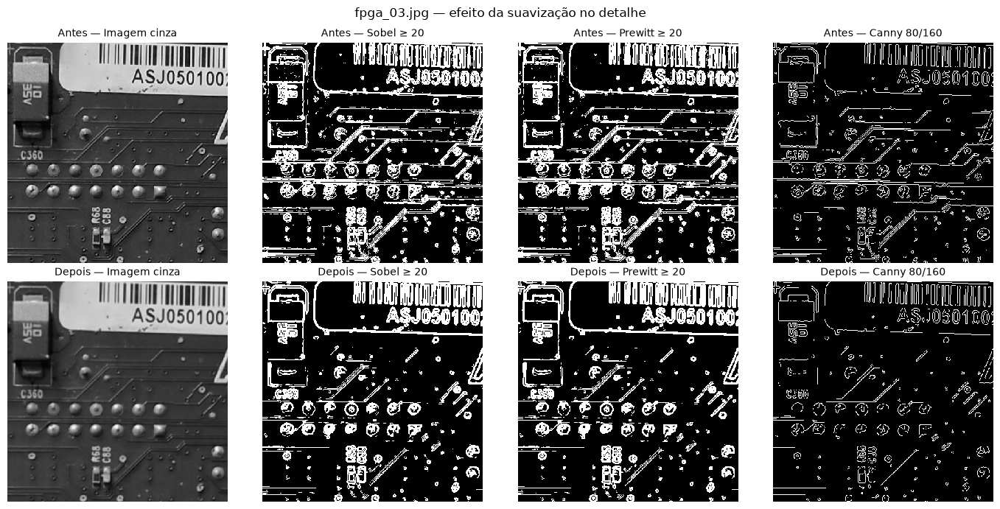

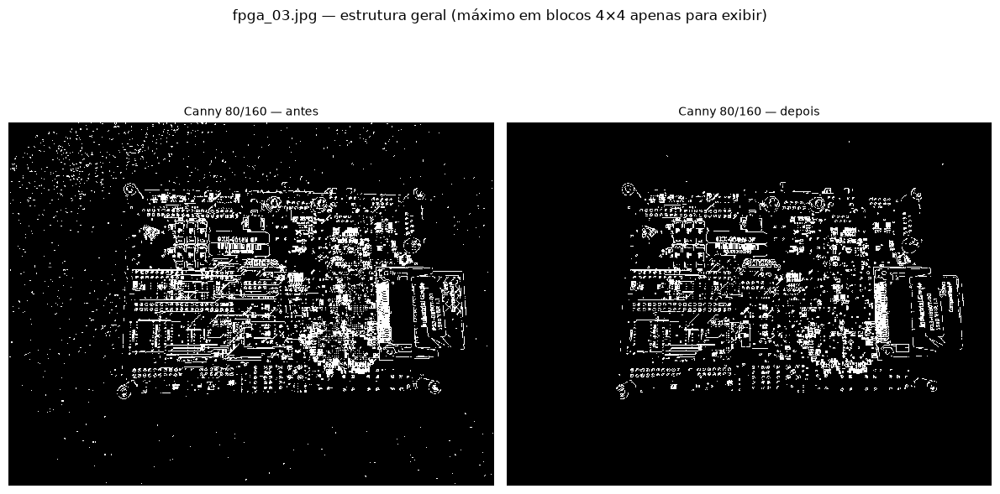

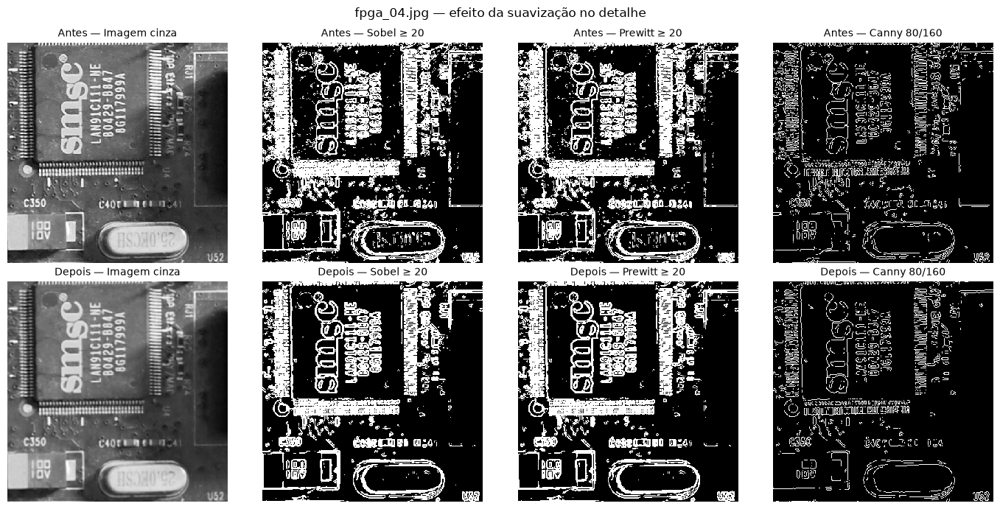

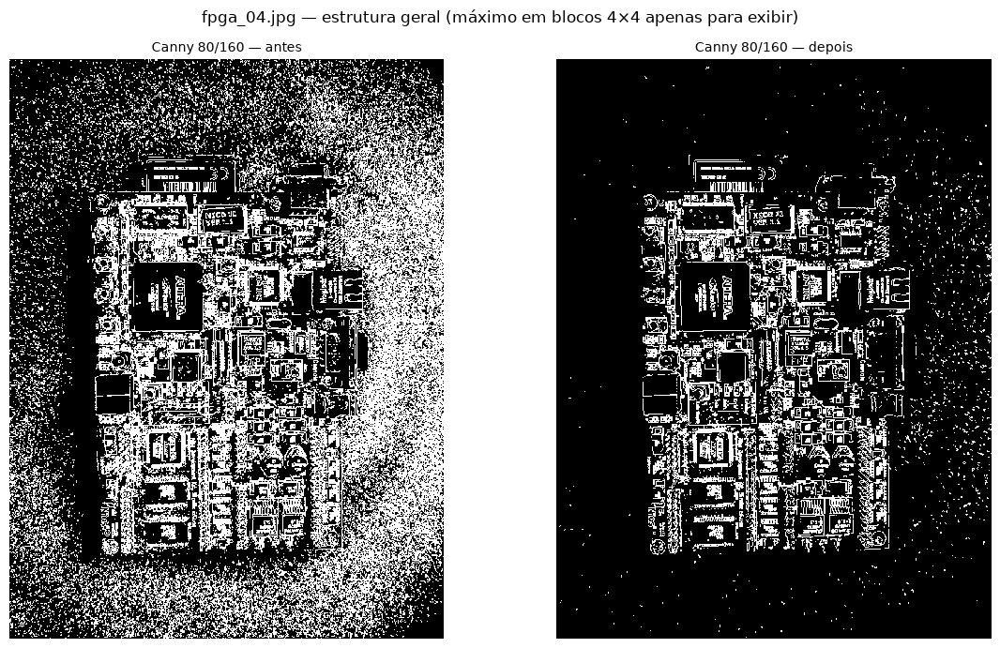

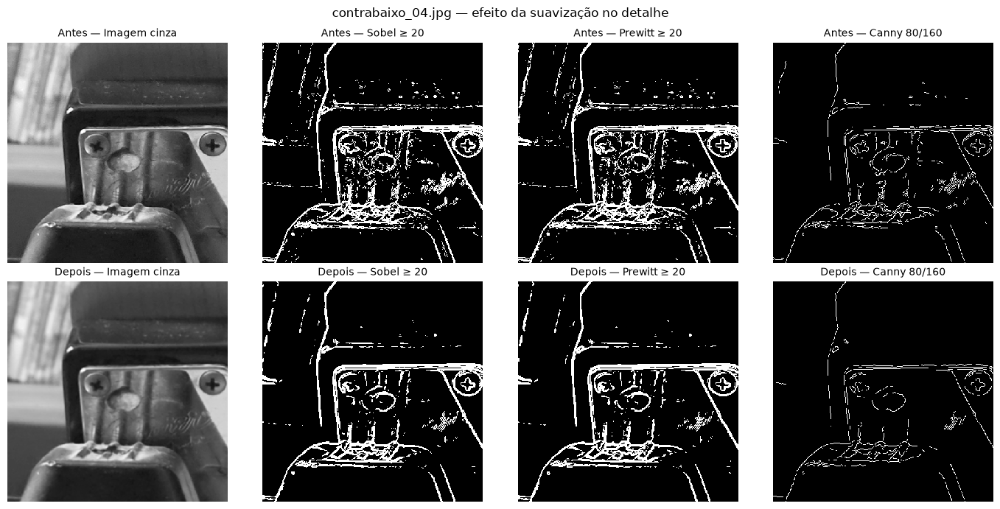

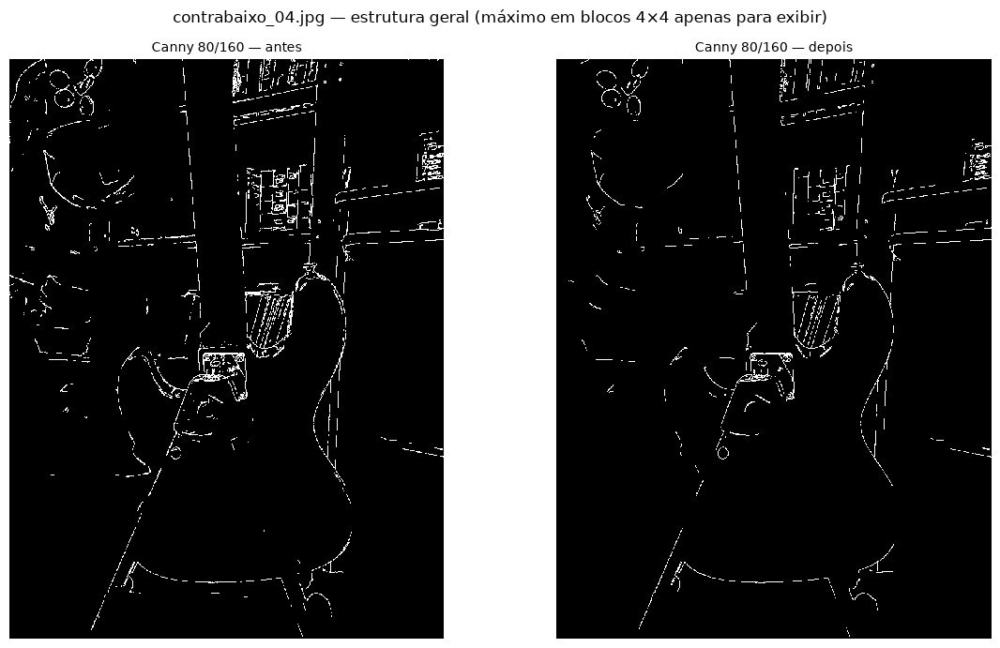

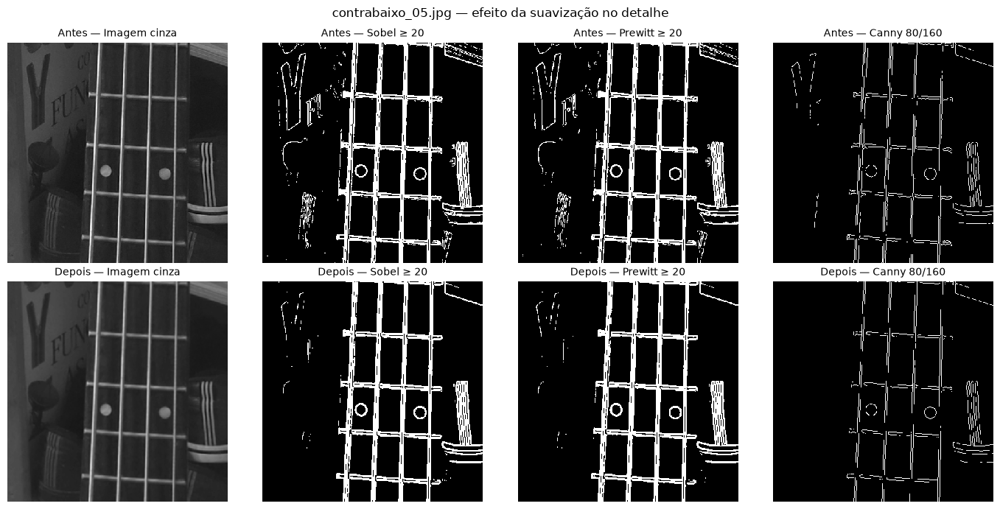

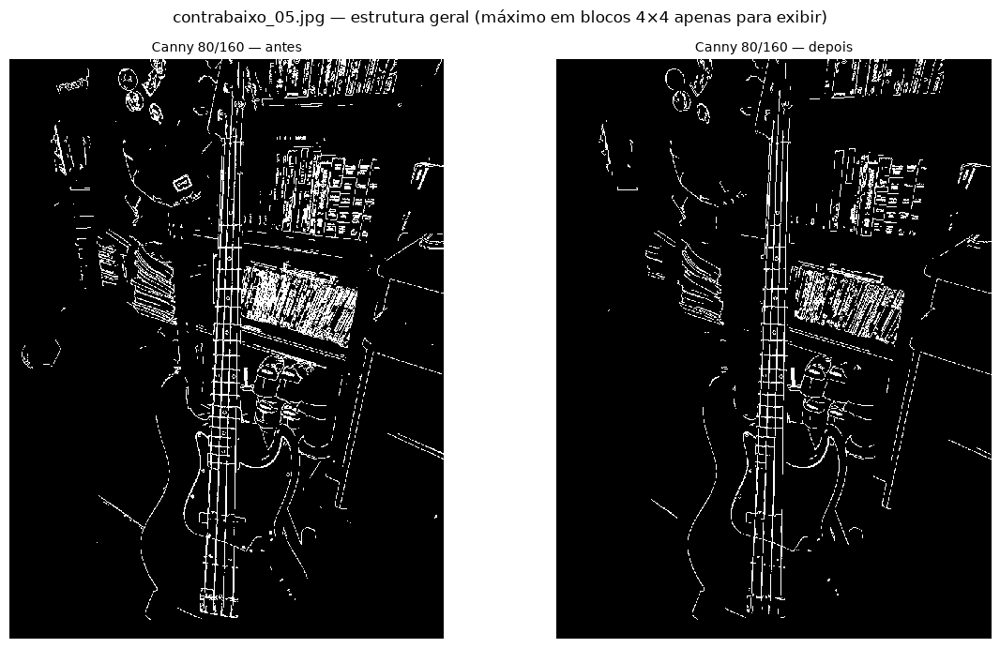

In [8]:
def ler_mascara(item, etapa, sufixo):
    caminho = (DERIVADAS / 'bordas' / etapa / item['classe'] /
               f"{Path(item['arquivo']).stem}_{sufixo}.png")
    with Image.open(caminho) as imagem:
        return np.array(imagem)

for item in SELECAO:
    nome = item['arquivo']
    figura, eixos = plt.subplots(2, 4, figsize=(14, 7))
    for linha, etapa in enumerate(['antes', 'depois']):
        entrada = IMAGENS[nome] if etapa == 'antes' else suavizar(IMAGENS[nome], FILTRO_ESCOLHIDO[nome])
        matrizes = [entrada] + [ler_mascara(item, etapa, sufixo)
                               for sufixo in ['sobel', 'prewitt', 'canny_80_160']]
        for coluna, (matriz, titulo) in enumerate(zip(matrizes,
                ['Imagem cinza', 'Sobel ≥ 20', 'Prewitt ≥ 20', 'Canny 80/160'])):
            eixos[linha, coluna].imshow(recortar(matriz, item['detalhe']), cmap='gray',
                                       vmin=0, vmax=255, interpolation='nearest')
            eixos[linha, coluna].set_title(f'{etapa.capitalize()} — {titulo}')
            eixos[linha, coluna].axis('off')
        del matrizes
    figura.suptitle(f'{nome} — efeito da suavização no detalhe')
    finalizar_figura(figura, f'comparacao_detalhe_{Path(nome).stem}')

    figura, eixos = plt.subplots(1, 2, figsize=(12, 7))
    for eixo, etapa in zip(eixos, ['antes', 'depois']):
        mascara = ler_mascara(item, etapa, 'canny_80_160')
        # Redução apenas para a vista geral, por máximo: preserva linhas finas na miniatura.
        h, w = mascara.shape
        vista_geral = mascara.reshape(h//4, 4, w//4, 4).max(axis=(1, 3))
        eixo.imshow(vista_geral, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        eixo.set_title(f'Canny 80/160 — {etapa}')
        eixo.axis('off')
    figura.suptitle(f'{nome} — estrutura geral (máximo em blocos 4×4 apenas para exibir)')
    finalizar_figura(figura, f'comparacao_geral_{Path(nome).stem}')

### Observações das imagens reais

| Imagem | Mudança após Gaussiano σ=1 e Canny 80/160 | Interpretação |
|---|---|---|
| fpga_03.jpg | Diminuem respostas pequenas; etiqueta e contornos fortes permanecem. Algumas trilhas ficam interrompidas. | Parte do que foi atenuado era sujeira ou detalhe real, e não ruído confirmado. |
| fpga_04.jpg | O tecido apresenta menos bordas e o circuito fica mais destacado. Inscrições e terminais perdem definição. | A textura do tecido foi suavizada, mas ela pertence à cena. Houve perda de informação junto com a redução das bordas. |
| contrabaixo_04.jpg | Diminuem pontos e transições no acabamento; junção e parafusos permanecem. Reflexos ainda geram bordas. | Reflexos não são ruído e não desaparecem corretamente por simples suavização. Alguns contornos fracos foram perdidos. |
| contrabaixo_05.jpg | Trastes, braço e marcadores permanecem; algumas cordas finas perdem resposta. | A filtragem não corrige a baixa exposição e pode eliminar estruturas importantes para reconhecer o instrumento. |

Visualmente, a suavização não trouxe uma melhoria clara para as fotografias originais.
Ela reduziu a quantidade de respostas, mas atenuou informações úteis. Sobel e Prewitt ficaram
muito próximos. Canny 80/160 produziu traços mais finos, porém isso não significa que seja
sempre mais robusto ao ruído. Neste conjunto, quase não havia ruído visível para testar essa
robustez; o experimento artificial é que permite observar o comportamento de cada filtro
em condições controladas.

## 6. Resumo dos resultados

A tabela reúne o Gaussiano σ=1 e o Canny 80/160 nas imagens reais. A média e a variância
dos seis filtros estão na seção 3. A redução abaixo é somente da quantidade de pixels
detectados como borda. Como sujeira, textura, reflexos e detalhes também produzem bordas,
essa porcentagem não representa quantidade de ruído removido nem ganho de qualidade.

In [9]:
linhas_sintese = []
for item in SELECAO:
    nome = item['arquivo']
    valores = suavizacao.query('imagem == @nome').set_index('filtro')
    filtro = FILTROS[FILTRO_ESCOLHIDO[nome]]
    r = canny_comparacao.query('imagem == @nome').iloc[0]
    linhas_sintese.append({'imagem': nome, 'filtro': filtro,
        'media_antes': valores.loc['Original', 'media_cinza'],
        'media_depois': valores.loc[filtro, 'media_cinza'],
        'variancia_antes': valores.loc['Original', 'variancia_cinza'],
        'variancia_depois': valores.loc[filtro, 'variancia_cinza'],
        'canny_antes': int(r['pixels_borda_antes']), 'canny_depois': int(r['pixels_borda_depois']),
        'reducao_bordas_percentual': r['reducao_pixels_percentual']})
sintese = pd.DataFrame(linhas_sintese)
sintese.to_csv(TABELAS / 'sintese.csv', index=False)
mostrar_tabela(sintese, {'imagem': 'Imagem', 'variancia_antes': 'Variância antes',
    'variancia_depois': 'Variância depois', 'canny_antes': 'Canny antes',
    'canny_depois': 'Canny depois', 'reducao_bordas_percentual': 'Redução de bordas (%)'})

,Imagem,Variância antes,Variância depois,Canny antes,Canny depois,Redução de bordas (%)
0,fpga_03.jpg,1172.60,1086.37,298156,194929,34.62
1,fpga_04.jpg,2214.84,2030.35,1192609,368582,69.09
2,contrabaixo_04.jpg,3644.16,3624.91,80613,47055,41.63
3,contrabaixo_05.jpg,1581.28,1538.22,229448,138169,39.78


## 7. Conclusão

A inspeção visual não mostrou ruído significativo nas quatro fotografias. Na FPGA, muitas
pequenas variações correspondem à sujeira da placa ou à textura real do material e do fundo.
No contrabaixo, as principais interferências são reflexos, iluminação desigual e baixa
exposição. O fundo desfocado em `contrabaixo_04.jpg` não deve ser confundido com ruído.

Os filtros mais fortes diminuíram a variância e a quantidade de bordas, mas também apagaram
trilhas, inscrições, cordas e contornos úteis. Portanto, a redução numérica não significou
necessariamente melhora. O Gaussiano σ=1 foi a opção menos agressiva usada na comparação
antes/depois, mas a imagem original ainda é preferível quando a tarefa depende de detalhes
finos. A suavização não remove corretamente sujeira e reflexos, pois eles fazem parte da cena.

Sobel e Prewitt apresentaram resultados semelhantes e bordas espessas. Canny produziu traços
mais finos, e o par 80/160 foi um valor intermediário entre manter respostas fracas e eliminar
detalhes. Depois do Gaussiano σ=1, os mapas ficaram visualmente mais limpos, porém algumas
estruturas reais ficaram interrompidas. Por isso, não foi possível afirmar melhora uniforme
nem decidir qual detector é mais robusto ao ruído usando somente essas fotos.

O experimento artificial ajudou a separar os conceitos. Para ruído gaussiano, média e
Gaussiano reduziram a granulação ao custo de nitidez. Para sal e pimenta, a mediana 3×3
removeu melhor os impulsos sem espalhar os valores extremos como a média. Esse resultado
mostra que a escolha do filtro depende da degradação presente. Aplicar suavização quando
não há ruído perceptível pode retirar mais informação do que acrescentar qualidade.

## Referências e arquivos necessários

Para executar, mantenha este notebook e as quatro fotos selecionadas nas pastas
`dataset/originais/fpga` e `dataset/originais/contrabaixo`. As imagens e tabelas dos
resultados já estão nas saídas das células. Os CSV e PNG são recriados ao executar.

- Enunciado: *Suavização, Remoção de Ruído e Detecção de Bordas*, Prof. Rafael Carmo.
- [OpenCV — suavização](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html).
- [OpenCV — gradientes](https://docs.opencv.org/4.x/d5/d0f/tutorial_py_gradients.html).
- [OpenCV — Canny](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html).